<a href="https://colab.research.google.com/github/Priyadarshini-yadav13/Transfer_learning/blob/main/Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1 Importing necessary libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split

#Step 2 Loading the dataset

In [ ]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
x_train.shape,y_train.shape,x_test.shape,y_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

#Step 3 Summarizing the dataset

In [ ]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
          0,   0,  13,  73,   0,   0,   1,   4,   0,   0,   0,   0,   1,
          1,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
          0,  36, 136, 127,  62,  54,   0,   0,   0,   1,   3,   4,   0,
          0,   3],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   6,
          0, 102, 204, 176, 134, 144, 123,  23,   0,   0,   0,   0,  12,
         10,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 155, 236, 207, 178, 107, 156, 161, 109,  64,  23,  77, 130,
         72,  15],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   0,
         69, 207, 223, 218, 216, 216, 163, 127, 121, 122, 146, 141,  88,
        172,  66],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   1,   1,   0,
        200, 232, 232, 233, 229, 223, 223, 215, 213, 164, 127, 123, 196,
        229,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        183, 225, 216, 223, 228, 235, 227, 224, 222, 224, 221, 223, 245,
        173,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        193, 228, 218, 213, 198, 180, 212, 210, 211, 213, 223, 220, 243,
        202,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   3,   0,  12,
        219, 220, 212, 218, 192, 169, 227, 208, 218, 224, 212, 226, 197,
        209,  52],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   6,   0,  99,
        244, 222, 220, 218, 203, 198, 221, 215, 213, 222, 220, 245, 119,
        167,  56],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   4,   0,   0,  55,
        236, 228, 230, 228, 240, 232, 213, 218, 223, 234, 217, 217, 209,
         92,   0],
       [  0,   0,   1,   4,   6,   7,   2,   0,   0,   0,   0,   0, 237,
        226, 217, 223, 222, 219, 222, 221, 216, 223, 229, 215, 218, 255,
         77,   0],
       [  0,   3,   0,   0,   0,   0,   0,   0,   0,  62, 145, 204, 228,
        207, 213, 221, 218, 208, 211, 218, 224, 223, 219, 215, 224, 244,
        159,   0],
       [  0,   0,   0,   0,  18,  44,  82, 107, 189, 228, 220, 222, 217,
        226, 200, 205, 211, 230, 224, 234, 176, 188, 250, 248, 233, 238,
        215,   0],
       [  0,  57, 187, 208, 224, 221, 224, 208, 204, 214, 208, 209, 200,
        159, 245, 193, 206, 223, 255, 255, 221, 234, 221, 211, 220, 232,
        246,   0],
       [  3, 202, 228, 224, 221, 211, 211, 214, 205, 205, 205, 220, 240,
         80, 150, 255, 229, 221, 188, 154, 191, 210, 204, 209, 222, 228,
        225,   0],
       [ 98, 233, 198, 210, 222, 229, 229, 234, 249, 220, 194, 215, 217,
        241,  65,  73, 106, 117, 168, 219, 221, 215, 217, 223, 223, 224,
        229,  29],
       [ 75, 204, 212, 204, 193, 205, 211, 225, 216, 185, 197, 206, 198,
        213, 240, 195, 227, 245, 239, 223, 218, 212, 209, 222, 220, 221,
        230,  67],
       [ 48, 203, 183, 194, 213, 197, 185, 190, 194, 192, 202, 214, 219,
        221, 220, 236, 225, 216, 199, 206, 186, 181, 177, 172, 181, 205,
        206, 115],
       [  0, 122, 219, 193, 179, 171, 183, 196, 204, 210, 213, 207, 211,
        210, 200, 196, 194, 191, 195, 191, 198, 192, 176, 156, 167, 177,
        210,  92],
       [  0,   0,  74, 189, 212, 191, 175, 172, 175, 181, 185, 188, 189,
        188, 193, 198, 204, 209, 210, 210, 211, 188, 188, 194, 192, 216,
        170,   0],
       [  2,   0,   0,   0,  66, 200, 22

In [ ]:
y_train[0]

np.uint8(9)

In [ ]:
x_test[1]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  13,  67,   0,
          0,   0,   0,  50,  38,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   8, 120, 209, 226, 247, 237,
        255, 255, 255, 247, 238, 235, 172,  72,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0, 137, 239, 252, 243, 234, 229, 238,
        244, 246, 240, 230, 232, 239, 248, 251, 194,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 102, 255, 231, 228, 227, 228, 233, 230,
        230, 229, 228, 232, 232, 231, 227, 224, 252, 179,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 233, 241, 229, 231, 255, 255, 238, 231,
        227, 238, 246, 228, 230, 227, 234, 235, 229, 241,  20,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 248, 241, 231, 255, 149,  47, 252, 228,
        255, 242, 216, 238, 232, 255, 228, 220, 234, 250,  54,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 255, 240, 232, 255,  15,   0, 255, 237,
        191,   0,   0, 214, 255,  13, 123, 255, 234, 252, 114,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   6, 255, 238, 239, 255, 177,   0, 255, 255,
          0, 130, 116,  47,  65,  43,  37, 255, 236, 249, 162,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  32, 255, 236, 245, 255, 204,   0, 255,  84,
          0,  37,  28,  31,   0,  25,  13, 255, 236, 249, 199,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  53, 255, 236, 250, 250, 231,   2, 255,  21,
          0, 221, 255, 236,  54, 245, 198, 243, 238, 245, 223,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  80, 255, 237, 250, 240, 255,   0,   0,  39,
        157,   0,   0, 215,  94,  20, 126, 255, 237, 239, 250,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 101, 255, 235, 253, 244, 243, 133, 138, 208,
        255, 201, 214, 255, 230,   7, 174, 255, 240, 238, 255,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 126, 255, 233, 255, 248, 233, 255, 255, 240,
        232, 243, 243, 231, 251, 255, 255, 254, 243, 238, 255,   3,   0,
          0,   0],
       [  0,   0,   0,   0, 147, 255, 233, 249, 181, 243, 227, 224, 230,
        234, 230, 230, 235, 228, 235, 222, 207, 255, 236, 255,  35,   0,
          0,   0],
       [  0,   0,   0,   0, 163, 255, 245, 221,  86, 255, 233, 233, 235,
        236, 234, 234, 234, 232, 242, 231, 125, 255, 236, 255,  55,   0,
          0,   0],
       [  0,   0,   0,   0, 181, 254, 255, 200,  69, 255, 228, 232, 234,
        235, 234, 234, 233, 235, 241, 237,  70, 255, 235, 246,  57,   0,
          0,   0],
       [  0,   0,   0,   0, 197, 247, 255, 188, 110, 255, 224, 233, 234,
        234, 234, 234, 234, 234, 240, 253,  69, 255, 236, 248,  77,   0,
          0,   0],
       [  0,   0,   0,   0, 200, 246, 255, 149, 145, 255, 223, 235, 234,
        235, 235, 235, 234, 237, 233, 255,  47, 255, 239, 249,  98,   0,
          0,   0],
       [  0,   0,   0,   0, 204, 243, 255, 111, 173, 255, 227, 235, 235,
        236, 235, 235, 235, 239, 229, 255,  19, 227, 246, 249, 110,   0,
          0,   0],
       [  0,   0,   0,   0, 196, 240, 255, 109, 213, 250, 229, 235, 235,
        236, 235, 237, 236, 237, 226, 255,  55, 203, 251, 245, 120,   0,
          0,   0],
       [  0,   0,   0,   0, 192, 243, 255, 114, 232, 240, 232, 235, 235,
        236, 234, 237, 236, 235, 229, 255, 134, 171, 252, 244, 137,   0,
          0,   0],
       [  0,   0,   0,   0, 189, 251, 255, 154, 238, 233, 236, 234, 235,
        236, 235, 238, 236, 235, 232, 255, 166, 125, 255, 243, 142,   0,
          0,   0],
       [  0,   0,   0,   0, 183, 252, 255, 171, 247, 232, 234, 234, 233,
        233, 232, 234, 233, 234, 233, 240, 223, 128, 255, 242, 151,   0,
          0,   0],
       [  0,   0,   0,   0, 178, 243, 255,  57, 238, 241, 238, 238, 238,
        237, 236, 237, 237, 240, 237, 254, 176,  52, 255, 239, 157,   0,
          0,   0],
       [  0,   0,   0,   0, 188, 240, 25

In [ ]:
y_test[1]

np.uint8(2)

In [ ]:
x_train[59999]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
          0,   1,  71,  13,   4,   0,   0,   1,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
          0,  62,  13,   0,  34,   0,   0,   0,   0,   0,   4,  42,  19,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
          0, 104,  68,   0,  51,  37,  28,  19,  47,  72,  95, 109,  59,
          0,   0],
       [  0,   0,   1,   0,   0,   1,   1,   0,   0,   1,   1,   0,   0,
          0,   0, 148, 133,  28,  42,  33,  27,  94,  98,  54,  97,  57,
          0,   3],
       [  1,   0,   1,   0,   4,   0,   0,   0,   0,   0,   0,   1,   0,
          6,   0,  27, 119, 101,   4,  75,  37,  27,  81, 130,  94,   0,
          0,   1],
       [  3,   1,   0,   0,   0,   0, 133, 157,   7,  21,   1,   0,   0,
          0,   0,   0,   0, 106, 145,  86,   4,  80, 124,  25,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   9,  56, 144, 133, 129, 153,  34,   0,   3,
          3,   0,   3,   0,  24, 104,  89, 104, 109,   0,   0,   0,   1,
          1,   0],
       [  1,   1,   3,   0,  25, 157, 170, 157, 201, 204,  25,   0,   0,
          0,   0,   0,   0,  51,  86,  94,  92,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,  37,  91,   0,   0,  86,   0,   0,   0,
         36,  92, 129, 148,  66, 100,  68,  98, 173, 133, 122, 136, 127,
        112,  21],
       [ 22,  27,  19,  37,  44,  83,  59,  56,  45,  51, 163, 177, 173,
        200, 176, 177, 188,  66, 122,  89,  92, 183, 174, 185, 180, 177,
        177,  47],
       [101, 235, 194, 223, 232, 255,  98,  75,  54, 136,  85, 218, 186,
        186, 168, 195, 177,  37,  48,  22,  77, 221, 191, 183, 180, 160,
        186,  57],
       [  4,  86,  62,  54,  34,  28,  95,  86,  81,  98,  78,  77,  83,
         75,  88,  88,  89,  63,  75,  81,  86,  88,  66,  51,  42,  21,
         18,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   

In [ ]:
y_train[59999]

np.uint8(5)

In [ ]:
class_labels = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

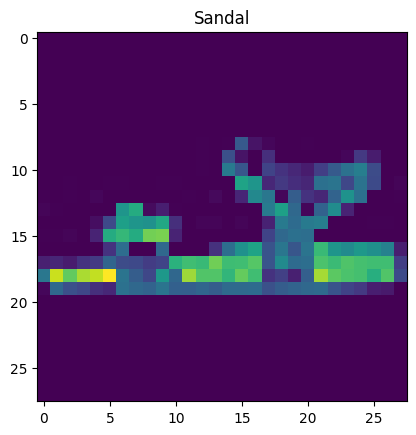

In [ ]:
#display one image
plt.imshow(x_train[59999])
plt.title(class_labels[y_train[59999]])
plt.show()

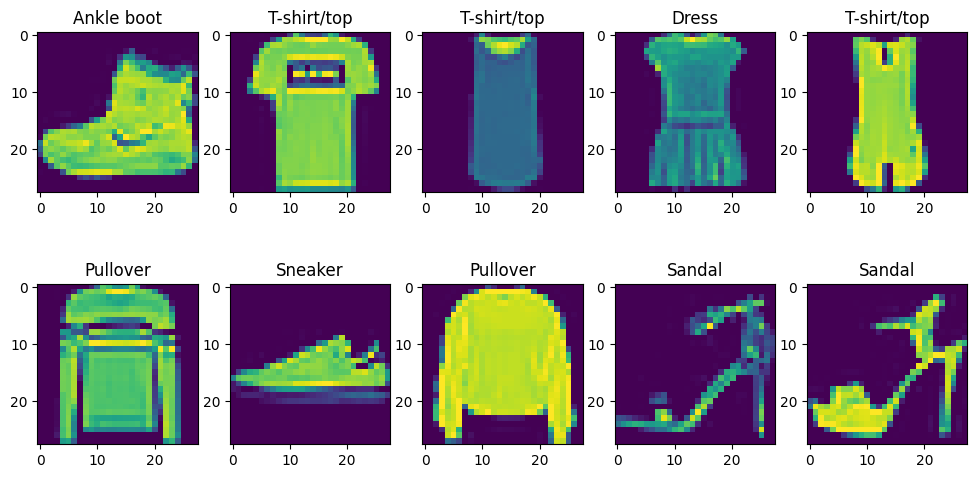

In [ ]:
plt.figure(figsize=(12,6))
for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(x_train[i])
  plt.title(class_labels[y_train[i]])

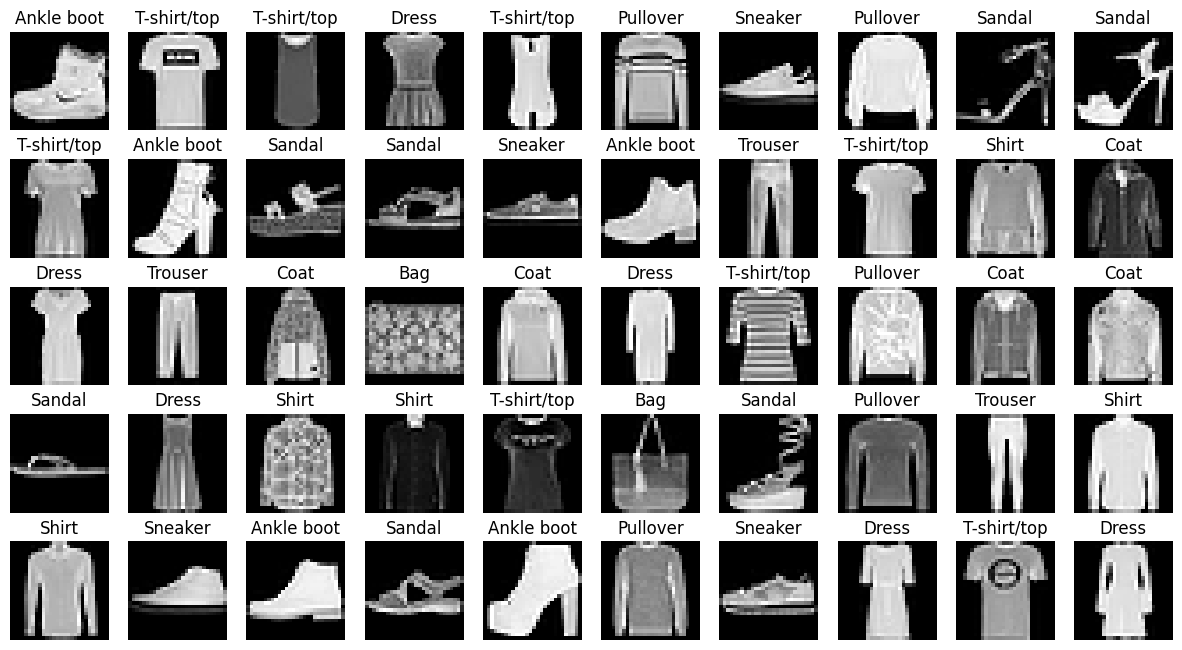

In [ ]:
plt.figure(figsize=(15,8))
for i in range(50):
  plt.subplot(5,10,i+1)
  plt.imshow(x_train[i], cmap='grey')
  plt.title(class_labels[y_train[i]])
  plt.axis('off')

#Step 4 : preprocessing the dataset

Preprocessing step 1 convert to float

In [ ]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
          0,   0,  13,  73,   0,   0,   1,   4,   0,   0,   0,   0,   1,
          1,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
          0,  36, 136, 127,  62,  54,   0,   0,   0,   1,   3,   4,   0,
          0,   3],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   6,
          0, 102, 204, 176, 134, 144, 123,  23,   0,   0,   0,   0,  12,
         10,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 155, 236, 207, 178, 107, 156, 161, 109,  64,  23,  77, 130,
         72,  15],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   0,
         69, 207, 223, 218, 216, 216, 163, 127, 121, 122, 146, 141,  88,
        172,  66],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   1,   1,   0,
        200, 232, 232, 233, 229, 223, 223, 215, 213, 164, 127, 123, 196,
        229,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        183, 225, 216, 223, 228, 235, 227, 224, 222, 224, 221, 223, 245,
        173,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        193, 228, 218, 213, 198, 180, 212, 210, 211, 213, 223, 220, 243,
        202,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   3,   0,  12,
        219, 220, 212, 218, 192, 169, 227, 208, 218, 224, 212, 226, 197,
        209,  52],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   6,   0,  99,
        244, 222, 220, 218, 203, 198, 221, 215, 213, 222, 220, 245, 119,
        167,  56],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   4,   0,   0,  55,
        236, 228, 230, 228, 240, 232, 213, 218, 223, 234, 217, 217, 209,
         92,   0],
       [  0,   0,   1,   4,   6,   7,   2,   0,   0,   0,   0,   0, 237,
        226, 217, 223, 222, 219, 222, 221, 216, 223, 229, 215, 218, 255,
         77,   0],
       [  0,   3,   0,   0,   0,   0,   0,   0,   0,  62, 145, 204, 228,
        207, 213, 221, 218, 208, 211, 218, 224, 223, 219, 215, 224, 244,
        159,   0],
       [  0,   0,   0,   0,  18,  44,  82, 107, 189, 228, 220, 222, 217,
        226, 200, 205, 211, 230, 224, 234, 176, 188, 250, 248, 233, 238,
        215,   0],
       [  0,  57, 187, 208, 224, 221, 224, 208, 204, 214, 208, 209, 200,
        159, 245, 193, 206, 223, 255, 255, 221, 234, 221, 211, 220, 232,
        246,   0],
       [  3, 202, 228, 224, 221, 211, 211, 214, 205, 205, 205, 220, 240,
         80, 150, 255, 229, 221, 188, 154, 191, 210, 204, 209, 222, 228,
        225,   0],
       [ 98, 233, 198, 210, 222, 229, 229, 234, 249, 220, 194, 215, 217,
        241,  65,  73, 106, 117, 168, 219, 221, 215, 217, 223, 223, 224,
        229,  29],
       [ 75, 204, 212, 204, 193, 205, 211, 225, 216, 185, 197, 206, 198,
        213, 240, 195, 227, 245, 239, 223, 218, 212, 209, 222, 220, 221,
        230,  67],
       [ 48, 203, 183, 194, 213, 197, 185, 190, 194, 192, 202, 214, 219,
        221, 220, 236, 225, 216, 199, 206, 186, 181, 177, 172, 181, 205,
        206, 115],
       [  0, 122, 219, 193, 179, 171, 183, 196, 204, 210, 213, 207, 211,
        210, 200, 196, 194, 191, 195, 191, 198, 192, 176, 156, 167, 177,
        210,  92],
       [  0,   0,  74, 189, 212, 191, 175, 172, 175, 181, 185, 188, 189,
        188, 193, 198, 204, 209, 210, 210, 211, 188, 188, 194, 192, 216,
        170,   0],
       [  2,   0,   0,   0,  66, 200, 22

In [ ]:
x_train_f = x_train.astype('float32')
x_test_f = x_test.astype('float32')

In [ ]:
x_train_f[0]

array([[  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   1.,   0.,   0.,  13.,  73.,   0.,   0.,   1.,   4.,   0.,
          0.,   0.,   0.,   1.,   1.,   0.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   3.,   0.,  36., 136., 127.,  62.,  54.,   0.,   0.,   0.,
          1.,   3.,   4.,   0.,   0.,   3.],
       [  0.,   0.,   0.,   0.,   0

In [ ]:
x_test_f[0]

array([[  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.],
       [  0.,   0.,   0.,   0.,   0

Preprocessing step 2 Add channel dimension

In [ ]:
x_train_f.shape

(60000, 28, 28)

In [ ]:
x_train_d = np.expand_dims(x_train_f, axis=-1)
x_test_d = np.expand_dims(x_test_f, axis=-1)

In [ ]:
x_train_d

array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
 

In [ ]:
x_test_d

array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
 

preprocessing step 3 resizing images from 28x28 to 32x32

In [ ]:
x_train_r = tf.image.resize(x_train_d,[32,32])

In [ ]:
x_train_r

<tf.Tensor: shape=(60000, 32, 32, 1), dtype=float32, numpy=
array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
  

In [ ]:
x_test_r = tf.image.resize(x_test_d,[32,32])

In [ ]:
x_test_r

<tf.Tensor: shape=(10000, 32, 32, 1), dtype=float32, numpy=
array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
  

preprocessing step 4 : convert grey scale to RGB  (from 32x32x1(1D) to 32x32x3(3D))

In [ ]:
x_train_rgb = tf.image.grayscale_to_rgb(x_train_r)

In [ ]:
x_train_rgb

<tf.Tensor: shape=(60000, 32, 32, 3), dtype=float32, numpy=
array([[[[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        ...,

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]]],




In [ ]:
x_test_rgb = tf.image.grayscale_to_rgb(x_test_r)

In [ ]:
x_test_rgb

<tf.Tensor: shape=(10000, 32, 32, 3), dtype=float32, numpy=
array([[[[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        ...,

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]]],




preprcessing step 5 : convert tensorflow tensor to numpy

In [ ]:
#convert tensorflow tensor to numpy
x_train_arr = x_train_rgb.numpy()
x_test_arr = x_test_rgb.numpy()

preprocessing step 6 : VGG-16 preprocessing

In [ ]:
#applying VGG-16 preprocessing
x_train_arr_vgg16 = preprocess_input(x_train_arr)

In [ ]:
x_test_arr_vgg16 = preprocess_input(x_test_arr)

preprocessing step 7 : preprocessing the output

In [ ]:
print(y_train)

[9 0 0 ... 3 0 5]


In [ ]:
y_test

array([9, 2, 1, ..., 8, 1, 5], dtype=uint8)

In [ ]:
y_train_hot = keras.utils.to_categorical(y_train)

In [ ]:
y_test_hot = keras.utils.to_categorical(y_test)

#Step 5 : Segregatting the Dataset into input and output

Input = images(x)

output = Class Labels(y)

#Step 6 : Splitting the dataset into training testing and validation



1.   training data = 60000

2.   Testing data = 10000

3.   Validation data = 20% of training data



In [ ]:
#splitting the training data into training and validation data
X_Train,X_Val,Y_Train,Y_Val = train_test_split(x_train_arr_vgg16,y_train_hot,test_size=0.2,random_state = 42)

In [ ]:
X_Train.shape

(48000, 32, 32, 3)

In [ ]:
X_Val.shape

(12000, 32, 32, 3)

In [ ]:
Y_Train.shape

(48000, 10)

In [ ]:
Y_Val.shape

(12000, 10)

In [ ]:
print("training data",X_Train.shape,Y_Train.shape)
print("Validation data",X_Val.shape,Y_Val.shape)
print("Testing data",x_test_arr_vgg16.shape,y_test_hot.shape)

training data (48000, 32, 32, 3) (48000, 10)
Validation data (12000, 32, 32, 3) (12000, 10)
Testing data (10000, 32, 32, 3) (10000, 10)


#Step 7 : Loading the pre-trained VGG-16 Model

In [ ]:
base_model=VGG16(weights="imagenet",include_top=False,input_shape=(32,32,3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

#Step 8 : Freezing the pre-trained layers

1.feature extraction

In [ ]:
base_model.trainable

True

In [ ]:
for layer in base_model.layers:
  print(layer.name,"-->",layer.trainable)

input_layer --> True
block1_conv1 --> True
block1_conv2 --> True
block1_pool --> True
block2_conv1 --> True
block2_conv2 --> True
block2_pool --> True
block3_conv1 --> True
block3_conv2 --> True
block3_conv3 --> True
block3_pool --> True
block4_conv1 --> True
block4_conv2 --> True
block4_conv3 --> True
block4_pool --> True
block5_conv1 --> True
block5_conv2 --> True
block5_conv3 --> True
block5_pool --> True


In [ ]:
base_model.trainable = False

In [ ]:
base_model.trainable

False

In [ ]:
for layer in base_model.layers:
  print(layer.name,"-->",layer.trainable)

input_layer --> False
block1_conv1 --> False
block1_conv2 --> False
block1_pool --> False
block2_conv1 --> False
block2_conv2 --> False
block2_pool --> False
block3_conv1 --> False
block3_conv2 --> False
block3_conv3 --> False
block3_pool --> False
block4_conv1 --> False
block4_conv2 --> False
block4_conv3 --> False
block4_pool --> False
block5_conv1 --> False
block5_conv2 --> False
block5_conv3 --> False
block5_pool --> False


In [ ]:
base_model.trainable

False

#Step 9 : Building the transfer learning Model

In [ ]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(10, activation='softmax')  # This only layer we r going to trainable
])

#Step 10 : Compiling the model

In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

Step 11 :Displaying the model

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,719,818 (56.15 MB)

 Trainable params: 5,130 (20.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

#Step 12 : Training the model

In [ ]:
history = model.fit(X_Train, Y_Train, epochs=10, validation_data=(X_Val, Y_Val), batch_size = 64)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 19s 18ms/step - accuracy: 0.7223 - loss: 2.2516 - val_accuracy: 0.7922 - val_loss: 1.0233
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8063 - loss: 0.8340 - val_accuracy: 0.8123 - val_loss: 0.7429
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8219 - loss: 0.6464 - val_accuracy: 0.8034 - val_loss: 0.8150
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8251 - loss: 0.5882 - val_accuracy: 0.8114 - val_loss: 0.6887
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8303 - loss: 0.5512 - val_accuracy: 0.8276 - val_loss: 0.6026
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8339 - loss: 0.5418 - val_accuracy: 0.8236 - val_loss: 0.6142
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8337 - loss: 0.5400 - val_accuracy: 0.8092 - val_loss: 0.6667
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8324 - loss: 0.5412 - 

#Step 13: Plot the training accuracy

In [ ]:
history.history

{'accuracy': [0.7223333120346069,
  0.8063125014305115,
  0.8219375014305115,
  0.825083315372467,
  0.8302708268165588,
  0.8339375257492065,
  0.8336874842643738,
  0.8323958516120911,
  0.8320624828338623,
  0.8343958258628845],
 'loss': [2.2515904903411865,
  0.8340467214584351,
  0.6464039087295532,
  0.5882335901260376,
  0.5512174367904663,
  0.541777491569519,
  0.5399646162986755,
  0.5411881804466248,
  0.5453140139579773,
  0.5343067049980164],
 'val_accuracy': [0.7921666502952576,
  0.812250018119812,
  0.8034166693687439,
  0.8114166855812073,
  0.8275833129882812,
  0.8235833048820496,
  0.809249997138977,
  0.8119166493415833,
  0.812666654586792,
  0.8305833339691162],
 'val_loss': [1.0233101844787598,
  0.742928683757782,
  0.8149999976158142,
  0.688674807548523,
  0.602636456489563,
  0.6141548156738281,
  0.6666697263717651,
  0.6784970164299011,
  0.6653767824172974,
  0.6199415922164917]}

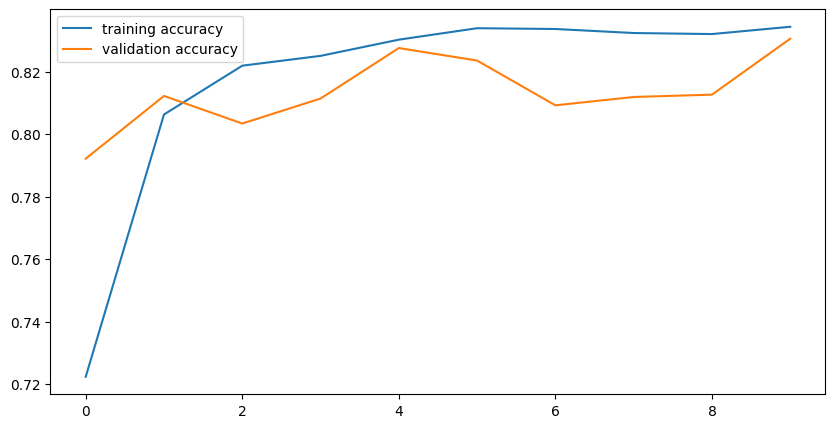

In [ ]:
plt.figure(figsize = (10,5))
plt.plot(history.history['accuracy'], label = 'training accuracy')
plt.plot(history.history['val_accuracy'], label = 'validation accuracy')
plt.legend()

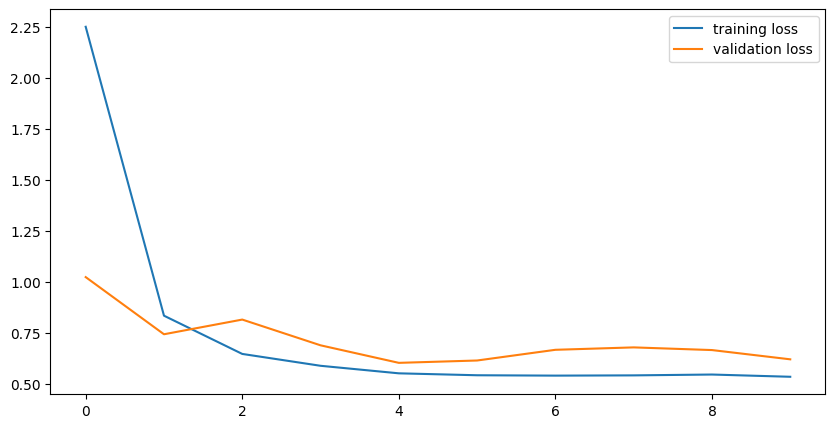

In [ ]:
plt.figure(figsize = (10,5))
plt.plot(history.history['loss'], label = 'training loss')
plt.plot(history.history['val_loss'], label = 'validation loss')
plt.legend()

#Step 14 : Evaluating the model

In [ ]:
model.evaluate(x_test_arr_vgg16,y_test_hot)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8236 - loss: 0.6473


[0.6473112106323242, 0.8235999941825867]

#Step 15 : Predicting the results for testdata

In [ ]:
Y_pred = model.predict(x_test_arr_vgg16)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step


In [ ]:
Y_pred

array([[2.5414351e-14, 8.0715601e-27, 4.0189144e-21, ..., 1.3036684e-02,
        6.6957967e-12, 9.8696005e-01],
       [1.4541103e-09, 2.0694382e-23, 9.9996722e-01, ..., 0.0000000e+00,
        2.7845124e-14, 1.4526462e-39],
       [2.0186557e-13, 1.0000000e+00, 6.6903544e-12, ..., 2.7532297e-24,
        2.9217170e-20, 2.6531683e-21],
       ...,
       [1.3257390e-10, 1.1126166e-15, 6.0074945e-10, ..., 7.5582108e-23,
        9.9997163e-01, 1.2868215e-25],
       [3.6690231e-10, 9.9977684e-01, 2.1554384e-07, ..., 4.4895652e-24,
        8.9904440e-13, 6.4674720e-22],
       [6.4779712e-08, 9.5640680e-17, 3.6798127e-11, ..., 9.9688393e-01,
        1.3095491e-03, 1.6405501e-03]], dtype=float32)

In [ ]:
Y_pred.shape

(10000, 10)

In [ ]:
Y_pred[0]

array([2.5414351e-14, 8.0715601e-27, 4.0189144e-21, 3.1263288e-14,
       2.5133250e-19, 3.2162352e-06, 1.5396402e-17, 1.3036684e-02,
       6.6957967e-12, 9.8696005e-01], dtype=float32)

In [ ]:
class_labels

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [ ]:
np.argmax(Y_pred[0])

np.int64(9)

In [ ]:
y_test_hot[0]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])

In [ ]:
x_test_arr_vgg16[0]

array([[[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       ...,

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [

#Step 16 : Predict the single image

In [ ]:
x_test_arr_vgg16[1]

array([[[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       ...,

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [

In [ ]:
x_test_arr_vgg16[1].shape

(32, 32, 3)

In [ ]:
x_test_arr_vgg16.shape

(10000, 32, 32, 3)

In [ ]:
x_test_arr_vgg16[1].reshape(1,32,32,3)

array([[[[-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         ...,
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ]],

        [[-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         ...,
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ]],

        [[-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         ...,
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ]],

        ...,

        [[-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         ...,
         [-103.939, -116.779, -123.68 ],
         [-103.939, -1

In [ ]:
prob_1 = model.predict(x_test_arr_vgg16[1].reshape(1,32,32,3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


In [ ]:
prob_1

array([[1.4540937e-09, 2.0692170e-23, 9.9996722e-01, 3.2357318e-11,
        3.1868186e-07, 4.5892525e-42, 3.2432246e-05, 0.0000000e+00,
        2.7846186e-14, 1.4524473e-39]], dtype=float32)

In [ ]:
np.argmax(prob_1)

np.int64(2)

In [ ]:
y_test_hot[1]

array([0., 0., 1., 0., 0., 0., 0., 0., 0., 0.])

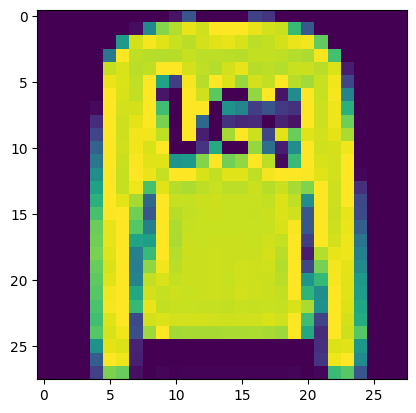

In [ ]:
plt.imshow(x_test[1])

In [ ]:
class_labels

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

#Step 17 :Fine Tuning

In [ ]:
base_model.trainable

False

In [ ]:
base_model.layers

[<InputLayer name=input_layer, built=True>,
 <Conv2D name=block1_conv1, built=True>,
 <Conv2D name=block1_conv2, built=True>,
 <MaxPooling2D name=block1_pool, built=True>,
 <Conv2D name=block2_conv1, built=True>,
 <Conv2D name=block2_conv2, built=True>,
 <MaxPooling2D name=block2_pool, built=True>,
 <Conv2D name=block3_conv1, built=True>,
 <Conv2D name=block3_conv2, built=True>,
 <Conv2D name=block3_conv3, built=True>,
 <MaxPooling2D name=block3_pool, built=True>,
 <Conv2D name=block4_conv1, built=True>,
 <Conv2D name=block4_conv2, built=True>,
 <Conv2D name=block4_conv3, built=True>,
 <MaxPooling2D name=block4_pool, built=True>,
 <Conv2D name=block5_conv1, built=True>,
 <Conv2D name=block5_conv2, built=True>,
 <Conv2D name=block5_conv3, built=True>,
 <MaxPooling2D name=block5_pool, built=True>]

In [ ]:
for i in base_model.layers:
  print(i.name,i.trainable)

input_layer False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 False
block5_conv2 False
block5_conv3 False
block5_pool False


In [ ]:
base_model.trainable = True

In [ ]:
for i in base_model.layers:
  print(i.name,i.trainable)

input_layer True
block1_conv1 True
block1_conv2 True
block1_pool True
block2_conv1 True
block2_conv2 True
block2_pool True
block3_conv1 True
block3_conv2 True
block3_conv3 True
block3_pool True
block4_conv1 True
block4_conv2 True
block4_conv3 True
block4_pool True
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


In [ ]:
#Freezing early layers

In [ ]:
for i in base_model.layers[:-4]:
  print(i)

<InputLayer name=input_layer, built=True>
<Conv2D name=block1_conv1, built=True>
<Conv2D name=block1_conv2, built=True>
<MaxPooling2D name=block1_pool, built=True>
<Conv2D name=block2_conv1, built=True>
<Conv2D name=block2_conv2, built=True>
<MaxPooling2D name=block2_pool, built=True>
<Conv2D name=block3_conv1, built=True>
<Conv2D name=block3_conv2, built=True>
<Conv2D name=block3_conv3, built=True>
<MaxPooling2D name=block3_pool, built=True>
<Conv2D name=block4_conv1, built=True>
<Conv2D name=block4_conv2, built=True>
<Conv2D name=block4_conv3, built=True>
<MaxPooling2D name=block4_pool, built=True>


In [ ]:
for i in base_model.layers[:-4]:
  i.trainable = False

In [ ]:
for i in base_model.layers:
  print(i.name,i.trainable)

input_layer False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


In [ ]:
#unfreez the last 4 layers
for i in base_model.layers[-4:]:
  i.trainable = True

In [ ]:
for i in base_model.layers:
  print(i.name,i.trainable)

input_layer False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


#Step 18 : Compiling the model

In [ ]:
model.compile(optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001),loss="categorical_crossentropy",metrics=["accuracy"])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,719,818 (56.15 MB)

 Trainable params: 7,084,554 (27.03 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

#Step 19 fine tuning the model

In [ ]:
history_fine = model.fit(X_Train, Y_Train, epochs=10, validation_data=(X_Val, Y_Val), batch_size = 64)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 21s 21ms/step - accuracy: 0.8650 - loss: 0.3956 - val_accuracy: 0.8637 - val_loss: 0.4226
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9002 - loss: 0.2762 - val_accuracy: 0.8744 - val_loss: 0.4041
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9201 - loss: 0.2195 - val_accuracy: 0.8797 - val_loss: 0.3980
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9337 - loss: 0.1808 - val_accuracy: 0.8860 - val_loss: 0.3756
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.9446 - loss: 0.1529 - val_accuracy: 0.8879 - val_loss: 0.3739
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.9527 - loss: 0.1329 - val_accuracy: 0.8862 - val_loss: 0.3902
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.9584 - loss: 0.1155 - val_accuracy: 0.8888 - val_loss: 0.4048
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.9649 - loss: 0.1011 - 

#Step 20 Evaluating finetuning model

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8236 - loss: 0.6473
[0.6473112106323242, 0.8235999941825867]

In [ ]:
model.evaluate(x_test_arr_vgg16,y_test_hot)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8915 - loss: 0.3979


[0.3979146182537079, 0.8914999961853027]

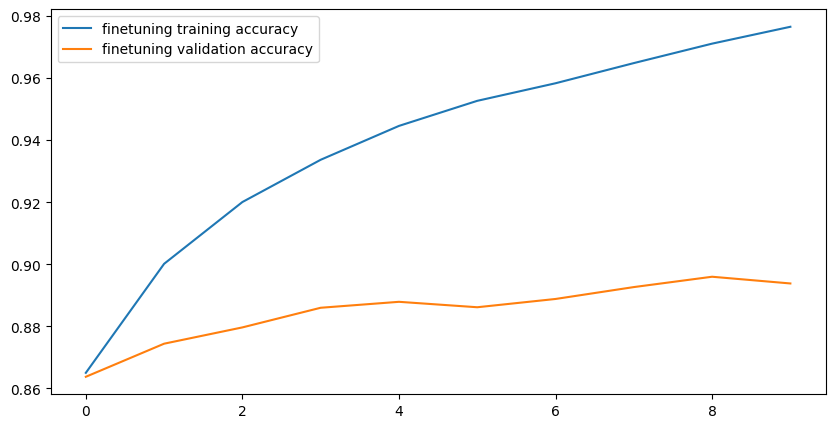

In [ ]:
plt.figure(figsize = (10,5))
plt.plot(history_fine.history['accuracy'], label = 'finetuning training accuracy')
plt.plot(history_fine.history['val_accuracy'], label = 'finetuning validation accuracy')
plt.legend()

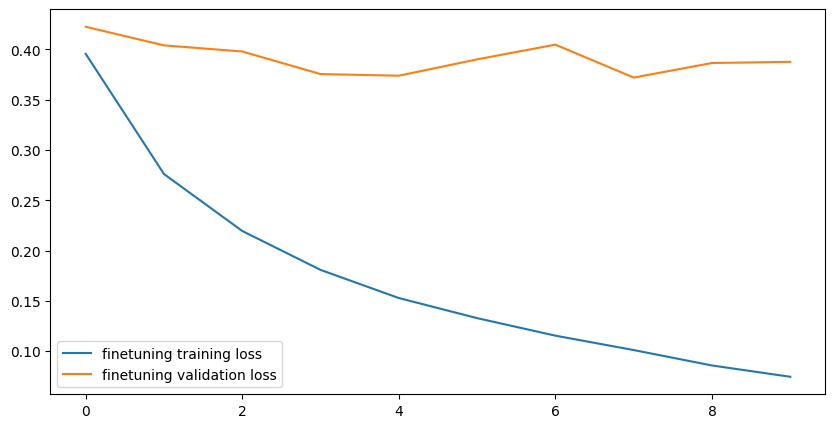

In [ ]:
plt.figure(figsize = (10,5))
plt.plot(history_fine.history['loss'], label = 'finetuning training loss')
plt.plot(history_fine.history['val_loss'], label = 'finetuning validation loss')
plt.legend()

In [ ]:
Y_pred = model.predict(x_test_arr_vgg16)

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step


In [ ]:
Y_pred

array([[4.70589887e-12, 1.15947760e-21, 1.87829846e-18, ...,
        3.76932207e-04, 8.47764133e-12, 9.99622941e-01],
       [3.14961881e-06, 1.79433308e-14, 9.99824524e-01, ...,
        1.29762305e-34, 2.44221569e-16, 1.47401439e-29],
       [3.50281347e-23, 1.00000000e+00, 3.25763526e-19, ...,
        1.21154676e-31, 1.70240363e-27, 3.96892069e-30],
       ...,
       [2.16805605e-14, 3.45420026e-20, 2.88744587e-13, ...,
        1.03064614e-22, 1.00000000e+00, 4.32949473e-29],
       [5.81277084e-19, 1.00000000e+00, 1.70758657e-13, ...,
        2.21569709e-29, 8.96479519e-24, 2.10373517e-28],
       [3.52074170e-09, 1.29567263e-17, 7.98473579e-11, ...,
        9.13852334e-01, 9.14453703e-05, 8.37162510e-02]], dtype=float32)

In [ ]:
x_test_arr_vgg16[1]

array([[[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       ...,

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [

In [ ]:
x_test_arr_vgg16[1].shape

(32, 32, 3)

In [ ]:
x_test_arr_vgg16.shape

(10000, 32, 32, 3)

In [ ]:
x_test_arr_vgg16[1].reshape(1,32,32,3)

array([[[[-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         ...,
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ]],

        [[-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         ...,
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ]],

        [[-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         ...,
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ]],

        ...,

        [[-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         [-103.939, -116.779, -123.68 ],
         ...,
         [-103.939, -116.779, -123.68 ],
         [-103.939, -1

In [ ]:
prob_1 = model.predict(x_test_arr_vgg16[1].reshape(1,32,32,3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step


array([[1.4540937e-09, 2.0692170e-23, 9.9996722e-01, 3.2357318e-11,

        3.1868186e-07, 4.5892525e-42, 3.2432246e-05, 0.0000000e+00,
        
        2.7846186e-14, 1.4524473e-39]], dtype=float32)

In [ ]:
prob_1

array([[3.1496429e-06, 1.7941823e-14, 9.9982452e-01, 3.6829777e-09,
        1.2029812e-04, 5.6402434e-37, 5.2106305e-05, 1.2975240e-34,
        2.4423462e-16, 1.4738232e-29]], dtype=float32)

In [ ]:
np.argmax(prob_1)

np.int64(2)

In [ ]:
y_test_hot[1]

array([0., 0., 1., 0., 0., 0., 0., 0., 0., 0.])

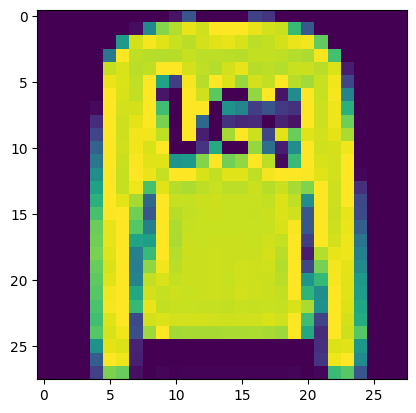

In [ ]:
plt.imshow(x_test[1])

In [ ]:
class_labels

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']